# Session 11 Practical: Overfitting and Underfitting

**Goal:** Train decision trees with different maximum depths and compare training and testing accuracy.

**Our story:** We want to predict whether a student will **Pass** or **Fail** an exam using two pieces of information:
- **Study Hours** - how many hours per week the student studies (0 to 10).
- **Marks** - the student's marks in a previous test (0 to 100).

The data is automatically generated (synthetic), so you can focus on the main idea instead of data cleaning.

### Key ideas before we start
- **Training data** is what the model learns from. It is like the practice questions a student studies.
- **Testing data** is kept hidden until the end. It is like the real exam with new questions.
- **Underfitting:** the model is too simple. It does badly on both training and testing data.
- **Overfitting:** the model is too complex. It memorizes the training data (even the random noise), so it does well on training data but worse on testing data.

By the end, you will be able to:
- Train decision trees with different `max_depth` values.
- Compare training and testing scores.
- Identify possible underfitting and overfitting.

## Step 1 - Import the tools

**What is happening?** Before we can work, we load the Python libraries (toolboxes) we need:
- `numpy` creates and handles numbers and random data.
- `pandas` stores data in tables (DataFrames).
- `matplotlib` draws graphs.
- `train_test_split` divides data into training and testing parts.
- `DecisionTreeClassifier` is the machine learning model we will use.
- `accuracy_score` measures what fraction of predictions are correct.

In [ ]:
import numpy as np                                    # numpy: tools for numbers, arrays and random data
import pandas as pd                                   # pandas: tools for tables (DataFrames)
import matplotlib.pyplot as plt                       # matplotlib: tools for drawing graphs

from sklearn.model_selection import train_test_split  # function that splits data into train and test sets
from sklearn.tree import DecisionTreeClassifier       # the decision tree model for classification (Pass/Fail)
from sklearn.metrics import accuracy_score            # function that calculates the percentage of correct predictions

print("Libraries imported successfully!")             # confirm that all imports worked without errors

Libraries imported successfully!


## Step 2 - Create a student dataset

**What is happening?** We create 300 imaginary students. For each student we generate:
1. **Study Hours** - a random number between 0 and 10.
2. **Marks** - a random number between 20 and 100 (marks in a previous test).
3. **Result** - Pass (1) or Fail (0).

How is the result decided? A student's chance of passing depends on both marks (60% importance) and study hours (40% importance). We also add:
- a little **random noise**, because real students are unpredictable (a good student may have a bad day), and
- a few **random flips** (about 8% of students), like a strong student who failed because they were sick.

This noise is important. A very deep tree will try to memorize this noise, and that is exactly what overfitting is.

**Class labels:** `0` = Fail and `1` = Pass.

In [ ]:
rng = np.random.RandomState(42)                          # create a random number generator; seed 42 makes results repeatable
n_students = 300                                         # total number of students in our dataset

study_hours = rng.uniform(0, 10, n_students)             # random study hours per week between 0 and 10 for each student
marks = rng.uniform(20, 100, n_students)                 # random marks in a previous test between 20 and 100

# combine both features into one "ability score" between about 0 and 1 (marks count 60%, study hours 40%)
score = 0.6 * (marks / 100) + 0.4 * (study_hours / 10)
score = score + rng.normal(0, 0.12, n_students)          # add random noise to make real-life unpredictability

y = (score > 0.55).astype(int)                           # students with score above 0.55 Pass (1), others Fail (0)

flip = rng.rand(n_students) < 0.08                       # randomly choose about 8% of students (True/False for each)
y[flip] = 1 - y[flip]                                    # flip their result (Pass becomes Fail, Fail becomes Pass) to add label noise

X = np.column_stack([study_hours, marks])                # put the two features side by side: column 0 = hours, column 1 = marks

data = pd.DataFrame(X, columns=["Study Hours", "Marks"]) # make a table with one column per feature
data["Result"] = y                                       # add the target column (0 = Fail, 1 = Pass)
data.head()                                              # show the first 5 students

,Study Hours,Marks,Result
0,3.745401,24.134538,0
1,9.507143,62.508371,1
2,7.319939,63.250810,1
3,5.986585,70.994392,0
4,1.560186,78.087307,0


## Step 3 - Visualize the dataset

**What is happening?** We draw a scatter plot. Each dot is one student:
- The **x-axis** shows Study Hours and the **y-axis** shows Marks.
- **Red** dots are students who passed. **Blue** dots are students who failed.

Look at the picture: students with high marks and many study hours usually pass, and students in the bottom-left usually fail. But near the middle the colors are mixed. That mixed area is where the noise is, and where models can easily make mistakes.

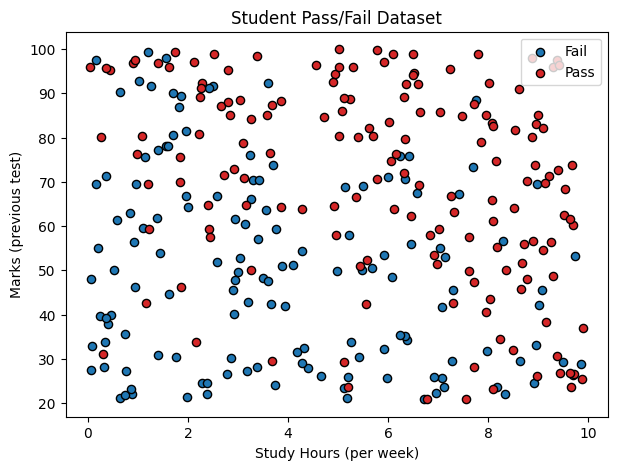

In [ ]:
plt.figure(figsize=(7, 5))                                # create a new empty figure 7 inches wide and 5 inches tall

# draw the Fail students (Result = 0) as blue dots
plt.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:blue", edgecolor="k", s=35, label="Fail")
# draw the Pass students (Result = 1) as red dots
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red", edgecolor="k", s=35, label="Pass")

plt.xlabel("Study Hours (per week)")                      # label for the horizontal axis
plt.ylabel("Marks (previous test)")                       # label for the vertical axis
plt.title("Student Pass/Fail Dataset")                    # title of the graph
plt.legend()                                              # show a box explaining which color means Pass or Fail
plt.show()                                                # display the finished graph

## Step 4 - Split into training and testing data

**What is happening?** We divide the 300 students into two groups:
- **70% training** (210 students): the model learns from these.
- **30% testing** (90 students): the model never sees these while learning. We use them to check how well the model works on *new* students.

Some important settings:
- `random_state=42` makes the split the same every time we run the code.
- `stratify=y` keeps the same proportion of Pass and Fail students in both groups, so the split is fair.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(     # split data; this returns four separate pieces
    X, y,                                                 # X = features (hours, marks), y = target (Pass/Fail)
    test_size=0.30,                                       # keep 30% of students for testing, 70% for training
    random_state=42,                                      # fixed seed so the same split happens every run
    stratify=y                                            # keep Pass/Fail proportions equal in train and test sets
)

print("Training examples:", len(X_train))                 # how many students the model will learn from
print("Testing examples:", len(X_test))                   # how many unseen students we will test on

Training examples: 210
Testing examples: 90


## Step 5 - Train decision trees with different depths

**What is happening?** A decision tree makes predictions by asking a series of yes/no questions, for example:
*"Is Marks less than 55?"* then *"Are Study Hours more than 4?"* and so on, until it decides Pass or Fail.

`max_depth` controls how many levels of questions the tree is allowed to ask:
- **Small depth** = simple tree (few questions). It may be too simple, which causes **underfitting**.
- **Large depth** = detailed tree (many questions). It may become too specific, which causes **overfitting**.
- `None` = no limit. The tree keeps asking questions until it classifies every training student correctly.

We loop through depths 1, 2, 3, 5 and `None`. For each depth we train a tree, then measure its accuracy on both the training students and the testing students.

In [ ]:
depth_values = [1, 2, 3, 5, None]                         # the different maximum depths we want to try
results = []                                              # empty list where we will store the scores of each tree

for depth in depth_values:                                # repeat the steps below once for every depth in the list
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)  # create a tree limited to this depth
    model.fit(X_train, y_train)                           # train the tree: it learns Pass/Fail rules from training students

    train_pred = model.predict(X_train)                   # predict Pass/Fail for the students it already studied
    test_pred = model.predict(X_test)                     # predict Pass/Fail for the new, unseen students

    results.append({                                      # save this tree's results as one row
        "Maximum Depth": str(depth),                      # depth as text (so None can be shown in the table and graph)
        "Training Accuracy": accuracy_score(y_train, train_pred),  # fraction of training students predicted correctly
        "Testing Accuracy": accuracy_score(y_test, test_pred)      # fraction of testing students predicted correctly
    })

results_df = pd.DataFrame(results)                        # convert the list of results into a table
results_df                                                # display the table

,Maximum Depth,Training Accuracy,Testing Accuracy
0,1,0.666667,0.644444
1,2,0.761905,0.733333
2,3,0.780952,0.722222
3,5,0.866667,0.722222
4,None,1.000000,0.733333


## Step 6 - Compare training and testing scores

**What is happening?** A table is useful, but a graph makes patterns easier to see. We draw a bar chart with two bars for each depth:
- One bar for **Training Accuracy** (how well the model does on students it studied).
- One bar for **Testing Accuracy** (how well it does on new students).

What to look for:
- Both bars low = the model is too simple (**underfitting**).
- Training bar very high but testing bar clearly lower = the model memorized the training data (**overfitting**).

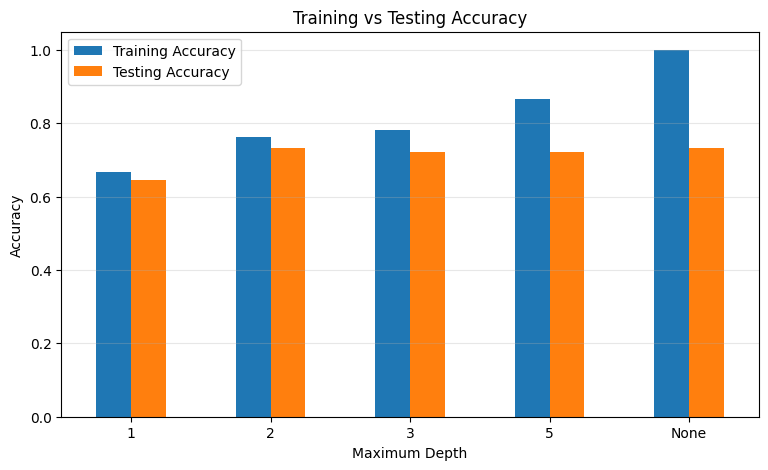

In [ ]:
results_df.set_index("Maximum Depth")[["Training Accuracy", "Testing Accuracy"]].plot(  # use depth as the x-axis, pick the 2 score columns
    kind="bar",                                           # draw a bar chart
    figsize=(9, 5),                                       # size of the figure (width 9, height 5 inches)
    ylim=(0, 1.05)                                        # y-axis from 0 to 1.05 (accuracy cannot be more than 1)
)
plt.ylabel("Accuracy")                                    # label for the vertical axis
plt.title("Training vs Testing Accuracy")                 # title of the graph
plt.xticks(rotation=0)                                    # keep the depth labels horizontal so they are easy to read
plt.grid(axis="y", alpha=0.3)                             # add light horizontal grid lines to help read the values
plt.show()                                                # display the finished graph

## Step 7 - Find the train-test gap

**What is happening?** The **gap** is simply: Training Accuracy minus Testing Accuracy.

- A **small gap** means the model performs similarly on seen and unseen students, which is good.
- A **large gap** can be a warning sign of **overfitting**. The model is great on practice questions but weak in the real exam.
- **Low scores on both sets** can indicate **underfitting**, even if the gap is small.

Remember that the gap alone is not enough. Always look at the gap *and* the testing accuracy together.

In [ ]:
results_df["Train-Test Gap"] = (                          # create a new column called "Train-Test Gap"
    results_df["Training Accuracy"] - results_df["Testing Accuracy"]   # subtract testing accuracy from training accuracy
)
results_df                                                # display the table again, now with the gap column

,Maximum Depth,Training Accuracy,Testing Accuracy,Train-Test Gap
0,1,0.666667,0.644444,0.022222
1,2,0.761905,0.733333,0.028571
2,3,0.780952,0.722222,0.058730
3,5,0.866667,0.722222,0.144444
4,None,1.000000,0.733333,0.266667


## Step 8 - Student questions

Answer these using your results table and graph:

1. Which depth has the lowest training accuracy?
2. Which depth gives the best testing accuracy?
3. At which depth does training accuracy become much higher than testing accuracy?
4. Does the unlimited-depth tree show evidence of overfitting?
5. What happens to the tree as maximum depth increases?

**Hint:** Overfitting may occur when training accuracy is very high but testing accuracy is noticeably lower.

## Optional - View a decision tree

**What is happening?** Here we draw the actual tree so you can see the questions it asks about **Study Hours** and **Marks**. Each box shows:
- the question (for example `Marks <= 55.2`),
- how many students reached that box (`samples`),
- how many are Fail and Pass (`value`),
- the predicted class (the color shows which class is the majority).

Change `chosen_depth` to 1, 3, or `None` and observe how the tree structure changes. With `None`, the tree can become very large.

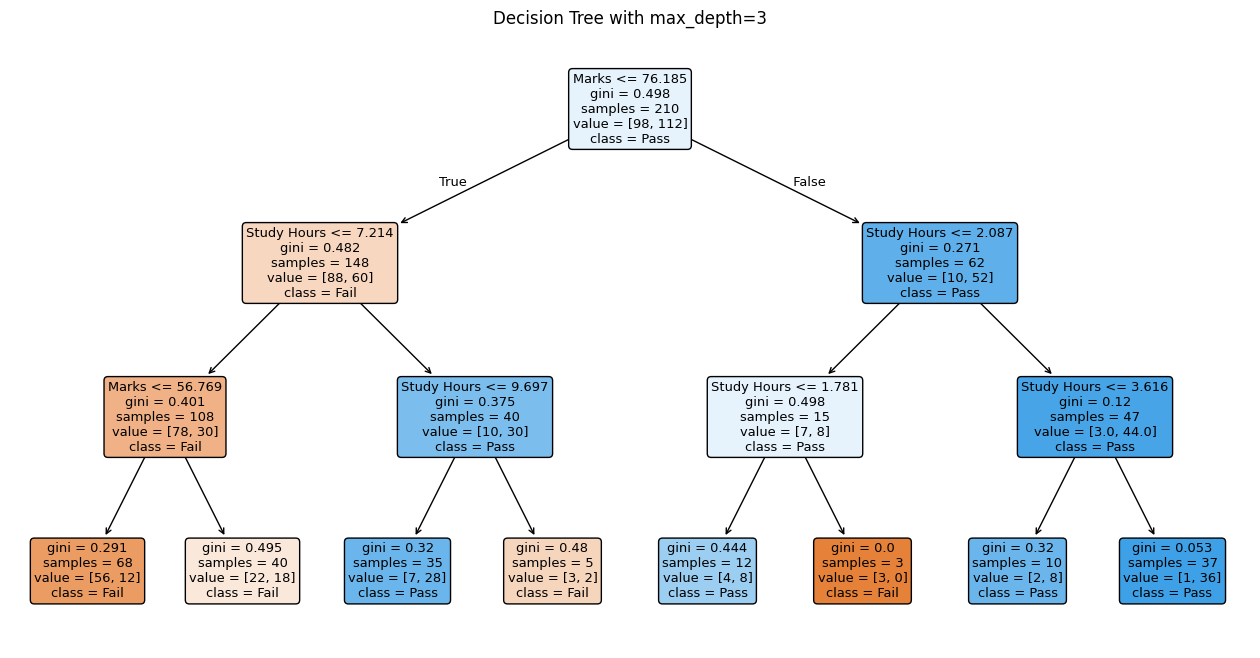

In [ ]:
from sklearn.tree import plot_tree                        # import the function that draws a decision tree

chosen_depth = 3                                          # change this to 1, 3 or None to compare different trees
example_tree = DecisionTreeClassifier(max_depth=chosen_depth, random_state=42)  # create a tree with the chosen depth
example_tree.fit(X_train, y_train)                        # train the tree on the training students

plt.figure(figsize=(16, 8))                               # make a big figure so the tree text is readable
plot_tree(
    example_tree,                                         # the trained tree we want to draw
    feature_names=["Study Hours", "Marks"],               # names of the features, shown in the questions
    class_names=["Fail", "Pass"],                         # names of the classes (0 = Fail, 1 = Pass)
    filled=True,                                          # color each box by its majority class
    rounded=True                                          # use rounded boxes (just for looks)
)
plt.title(f"Decision Tree with max_depth={chosen_depth}") # title that shows which depth is being displayed
plt.show()                                                # display the tree

## Final conclusion

Complete these sentences in your own words:

- A model is **underfitting** when ...
- A model is **overfitting** when ...
- We compare training and testing scores because ...
- Increasing decision-tree depth makes the model ...

**Remember:** the deepest tree is not automatically the best tree. We want a model that predicts well on new, unseen students, not one that only memorizes the students it has already seen.